# Лабораторная 3. Временные ряды. Сглаживание.
**Выполнила:** Окулова Александра ИТ-14

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests

from io import BytesIO
from statsmodels.tsa.api import SimpleExpSmoothing, Holt, ExponentialSmoothing


def run_sequence_plot(x, y, title, xlabel="Время", ylabel="Значения", ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(10, 3.5))
    ax.plot(x, y, 'g-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    difference = observations - estimates
    sq_diff = difference ** 2
    mse = np.mean(sq_diff)
    return mse


### Упражнения

Загрузите следующие два временных ряда.

In [2]:
# Load the first time series
response = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts1.npy?download=1")
response.raise_for_status()
smoothing_ts1 = np.load(BytesIO(response.content))
print(len(smoothing_ts1))

# Load the second time series
response = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts4_4.npy?download=1")
response.raise_for_status()
smoothing_ts2 = np.load(BytesIO(response.content))
print(len(smoothing_ts2))

144
1000


Используя то, что вы узнали в этой и предыдущих лекциях, выполните следующие действия.

1. Создайте две временные переменные с именами mytime1 и mytime2, которые начинаются с 0 и имеют такую ​​же длину, как и каждый набор данных.
2. Разделите каждый набор данных на обучающий и тестовый наборы (в качестве теста используйте последние 5 наблюдений).
3. Определите тренд и сезонность, если они присутствуют.
4. Определите, являются ли тренд и/или сезонность аддитивными или мультипликативными, если они присутствуют.
5. Создайте сглаженную модель на обучающем наборе и используйте ее для прогнозирования на тестовом наборе.
6. Рассчитайте MSE на тестовых данных.
7. Нанесите на график обучающие данные, тестовые данные и прогноз вашей модели для каждого набора данных.


In [3]:
#1. Создание временных переменных
mytime1 = np.arange(len(smoothing_ts1))
mytime2 = np.arange(len(smoothing_ts2))
print("Длина первого ряда:", len(mytime1))
print("Длина второго ряда:", len(mytime2))

Длина первого ряда: 144
Длина второго ряда: 1000


In [4]:
#2. Разделение на обучающую и тестовую выборки
train1 = smoothing_ts1[:-5]
test1 = smoothing_ts1[-5:]
train2 = smoothing_ts2[:-5]
test2 = smoothing_ts2[-5:]

print("Первый ряд")
print("Обучающая выборка:", len(train1))
print("Тестовая выборка:", len(test1))
print("\nВторой ряд")
print("Обучающая выборка:", len(train2))
print("Тестовая выборка:", len(test2))


Первый ряд
Обучающая выборка: 139
Тестовая выборка: 5

Второй ряд
Обучающая выборка: 995
Тестовая выборка: 5


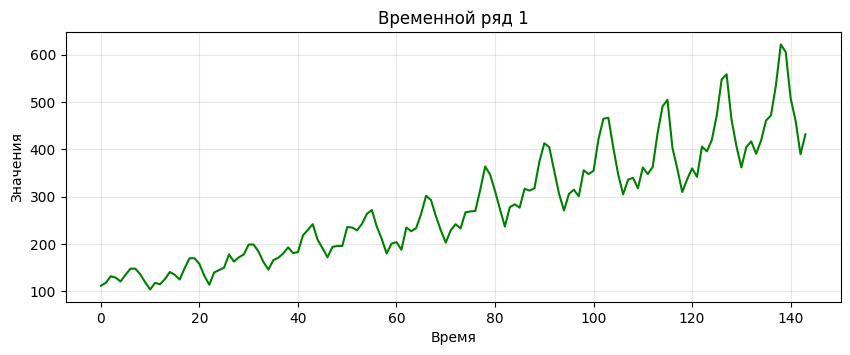

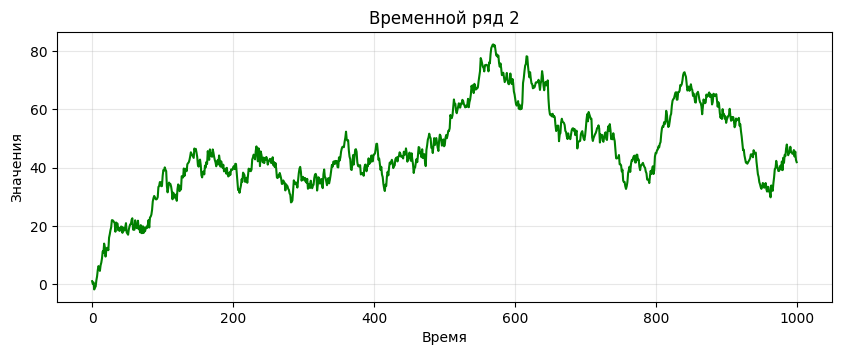

In [5]:
#3. Анализ тренда и сезонности
run_sequence_plot(mytime1, smoothing_ts1,
                  title="Временной ряд 1")
run_sequence_plot(mytime2, smoothing_ts2,
                  title="Временной ряд 2")
plt.show()

### 3,4. Анализ тренда и сезонности

**Временной ряд 1**

Наблюдается восходящий тренд и выраженная сезонность с периодом 12 наблюдений. Тренд можно считать аддитивным, поскольку средний уровень ряда увеличивается приблизительно линейно. Сезонность является мультипликативной, так как амплитуда сезонных колебаний увеличивается вместе с уровнем ряда.

**Временной ряд 2**

Выраженный устойчивый тренд отсутствует. Наблюдаются нерегулярные периоды роста и снижения значений. Сезонность с постоянным периодом не выявлена.

Для прогнозирования первого ряда выбран метод Хольта - Уинтерса, для второго простое экспоненциальное сглаживание.

In [6]:
#5. Создание модели для первого ряда
model1 = ExponentialSmoothing(
    train1,
    trend="additive",
    seasonal="multiplicative",
    seasonal_periods=12
).fit(optimized=True)

forecast1 = model1.forecast(len(test1))

print("Прогноз первого ряда:")
print(forecast1)

Прогноз первого ряда:
[626.70199766 512.59675228 447.67714675 392.50385034 432.18182224]


In [7]:
#Создание модели для второго ряда
model2 = SimpleExpSmoothing(
    train2,
    initialization_method="estimated"
).fit(optimized=True)

forecast2 = model2.forecast(len(test2))

print("Прогноз второго ряда:")
print(forecast2)

Прогноз второго ряда:
[44.78222362 44.78222362 44.78222362 44.78222362 44.78222362]


In [8]:
#6. Расчёт MSE
mse1 = mse(test1, forecast1)
mse2 = mse(test2, forecast2)

print("Первый временной ряд")
print("Реальные значения:", test1)
print("Прогноз:", forecast1)
print(f"MSE: {mse1:.3f}")
print("\nВторой временной ряд")
print("Реальные значения:", test2)
print("Прогноз:", forecast2)
print(f"MSE: {mse2:.3f}")


Первый временной ряд
Реальные значения: [606 508 461 390 432]
Прогноз: [626.70199766 512.59675228 447.67714675 392.50385034 432.18182224]
MSE: 126.701

Второй временной ряд
Реальные значения: [46.04384344 43.84007603 45.51910124 42.64285148 41.89935838]
Прогноз: [44.78222362 44.78222362 44.78222362 44.78222362 44.78222362]
MSE: 3.182


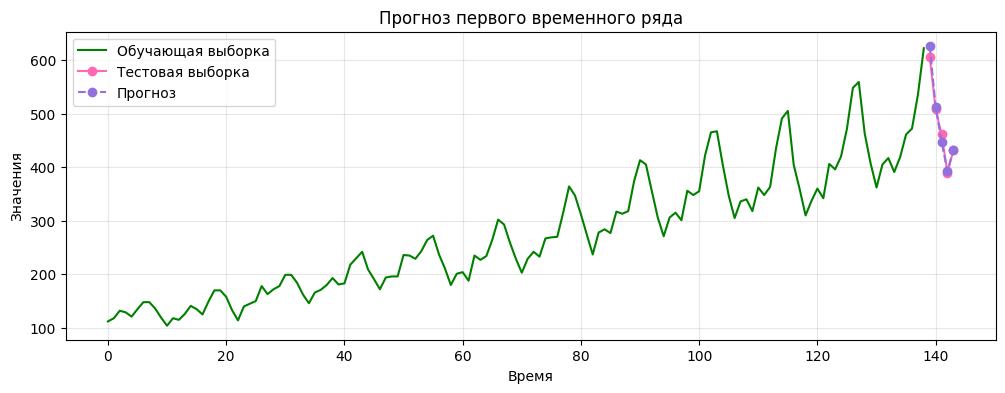

In [9]:
#7. График прогноза первого ряда
plt.figure(figsize=(12, 4))
plt.plot(mytime1[:-5], train1,
         color="green", label="Обучающая выборка")
plt.plot(mytime1[-5:], test1,
         color="hotpink", marker="o", label="Тестовая выборка")
plt.plot(mytime1[-5:], forecast1,
         color="mediumpurple", marker="o",
         linestyle="--", label="Прогноз")

plt.title("Прогноз первого временного ряда")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


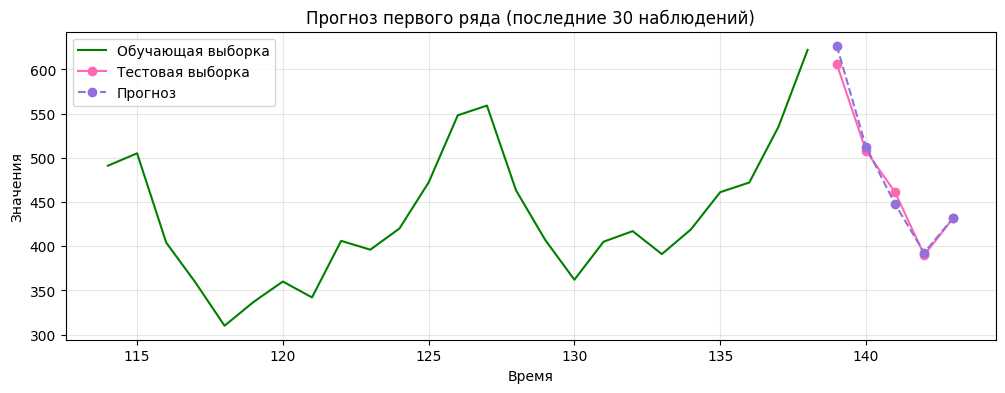

In [16]:
#Доп. построение первого ряда
plt.figure(figsize=(12, 4))

plt.plot(mytime1[-30:-5], train1[-25:],
         color="green", label="Обучающая выборка")
plt.plot(mytime1[-5:], test1,
         color="hotpink", marker="o", label="Тестовая выборка")
plt.plot(mytime1[-5:], forecast1,
         color="mediumpurple", marker="o",
         linestyle="--", label="Прогноз")

plt.title("Прогноз первого ряда (последние 30 наблюдений)")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


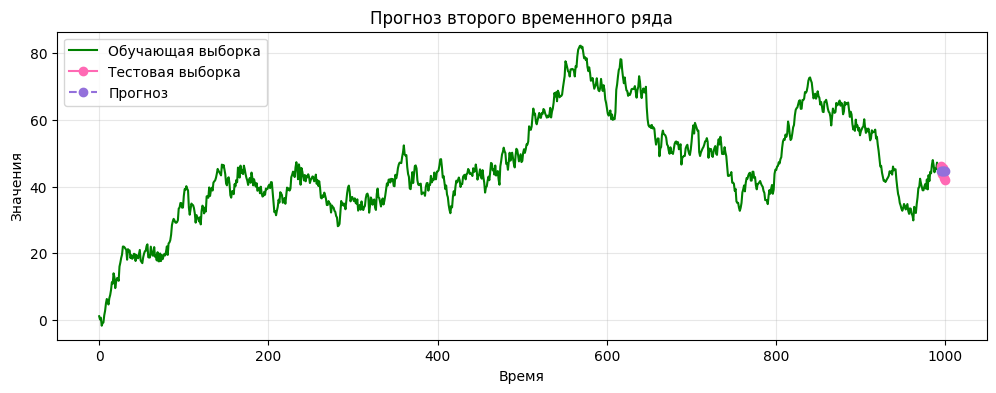

In [10]:
#График прогноза второго ряда
plt.figure(figsize=(12, 4))

plt.plot(mytime2[:-5], train2,
         color="green", label="Обучающая выборка")
plt.plot(mytime2[-5:], test2,
         color="hotpink", marker="o", label="Тестовая выборка")
plt.plot(mytime2[-5:], forecast2,
         color="mediumpurple", marker="o",
         linestyle="--", label="Прогноз")

plt.title("Прогноз второго временного ряда")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


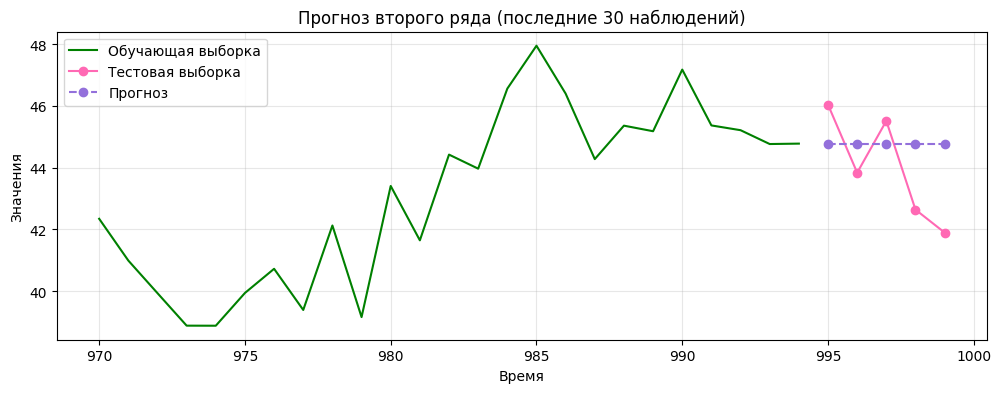

In [11]:
#Доп. построение второго ряда
plt.figure(figsize=(12, 4))

plt.plot(mytime2[-30:-5], train2[-25:],
         color="green", label="Обучающая выборка")
plt.plot(mytime2[-5:], test2,
         color="hotpink", marker="o", label="Тестовая выборка")
plt.plot(mytime2[-5:], forecast2,
         color="mediumpurple", marker="o",
         linestyle="--", label="Прогноз")

plt.title("Прогноз второго ряда (последние 30 наблюдений)")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Вывод

В ходе лабораторной работы были исследованы два временных ряда и построены модели экспоненциального сглаживания для прогнозирования их будущих значений.

Для первого временного ряда выявлены восходящий аддитивный тренд и мультипликативная сезонность с периодом 12 наблюдений. Для прогнозирования был выбран метод Хольта - Уинтерса. Модель успешно воспроизводит сезонные изменения ряда. Среднеквадратичная ошибка на тестовой выборке составила MSE = 126.701.

Для второго временного ряда не выявлено устойчивого тренда и выраженной сезонности. Был применён метод простого экспоненциального сглаживания. Полученный прогноз имеет постоянное значение 44.782. Среднеквадратичная ошибка составила MSE = 3.182.

В результате построены графики обучающих и тестовых данных, а также прогнозов обеих моделей.

Таким образом, методы экспоненциального сглаживания позволяют прогнозировать временные ряды с различными характеристиками. Выбор модели зависит от наличия тренда, сезонности и их типа.